In [1]:
import pandas as pd
import os
from glob import glob
import re

import matplotlib.pyplot as plt
import seaborn as sns

# import ipywidgets as ipw

In [2]:
data_folder = 'Vol_Surf_files/'

files = glob(data_folder + '/**/*.csv*', recursive=True)
files

['Vol_Surf_files\\230524_pt1_FR_5min_TP_8ss.csv',
 'Vol_Surf_files\\230524_pt2_FR_5min_TP_8ss.csv',
 'Vol_Surf_files\\230524_pt4_FR_5min_TP_8ss.csv']

In [3]:
import re
import numpy as np
import pandas as pd

dfs = []
for file in files:
    fname = file.split("\\")[-1]
    
    fr_matches = re.findall("_([0-9]+)min", fname)
    ss_matches = re.findall("([0-9]+)ss", fname)
    
    # Check if matches were found
    if fr_matches:
        fr = fr_matches[0]
    else:
        print(f"No 'min' found in filename: {fname}")
        continue  # Skip this iteration if no match found

    if ss_matches:
        ss = ss_matches[0]
    else:
        print(f"No 'ss' found in filename: {fname}")
        continue  # Skip this iteration if no match found
    
    # Change from read_excel to read_csv
    df = pd.read_csv(file)
    
    # Filter out unnamed columns
    cols = [col for col in df.columns if 'Unnamed' not in col]
    df = df[cols].copy()
    
    # Rename columns accordingly
    df.rename(columns=dict(zip(cols, ["Mesh Number", "Mesh Volume", "Surface Area", "Volume in um³", "Surface in um²", "Volume to Area Ratio"])), inplace=True)
    
    df['path'] = file
    df['fname'] = fname
    df['FR'] = pd.to_numeric(fr)
    df['SS'] = pd.to_numeric(ss)
    df['dTime_min'] = (df['Mesh Number'] - 1) * pd.to_numeric(fr)
    dfs.append(df)
    print(df.fname) 
    print(df.columns)

# Concatenate all dataframes
data = pd.concat(dfs)

min_ss = data['SS'].min()
data['Time'] = data.apply(lambda r: r['dTime_min'] + 30 * (r['SS'] - min_ss), axis=1)

# --- Shape descriptors ---------------------------------------------------
# NOTE: for every embryo each frame = 5 min, so FR is 5 for all these files
# and Time is in MINUTES. Every slope below is therefore per MINUTE.
# True Wadell sphericity: Psi = pi^(1/3) * (6V)^(2/3) / A  -> 1 for a sphere, <1 otherwise.
data['Sphericity'] = np.pi**(1/3) * (6 * data['Volume in um³'])**(2/3) / data['Surface in um²']
# Normalised V/A^1.5 (what later cells call the 'ratio'); equals Sphericity**1.5, =1 for a sphere.
data['V/A^1.5 (norm)'] = (data['Volume in um³'] / data['Surface in um²']**1.5) * 6 * np.sqrt(np.pi)



0     230524_pt1_FR_5min_TP_8ss.csv
1     230524_pt1_FR_5min_TP_8ss.csv
2     230524_pt1_FR_5min_TP_8ss.csv
3     230524_pt1_FR_5min_TP_8ss.csv
4     230524_pt1_FR_5min_TP_8ss.csv
                  ...              
68    230524_pt1_FR_5min_TP_8ss.csv
69    230524_pt1_FR_5min_TP_8ss.csv
70    230524_pt1_FR_5min_TP_8ss.csv
71    230524_pt1_FR_5min_TP_8ss.csv
72    230524_pt1_FR_5min_TP_8ss.csv
Name: fname, Length: 73, dtype: object
Index(['Mesh Number', 'Mesh Volume', 'Surface Area', 'Volume in um³',
       'Surface in um²', 'Volume to Area Ratio', 'path', 'fname', 'FR', 'SS',
       'dTime_min'],
      dtype='object')
0     230524_pt2_FR_5min_TP_8ss.csv
1     230524_pt2_FR_5min_TP_8ss.csv
2     230524_pt2_FR_5min_TP_8ss.csv
3     230524_pt2_FR_5min_TP_8ss.csv
4     230524_pt2_FR_5min_TP_8ss.csv
                  ...              
70    230524_pt2_FR_5min_TP_8ss.csv
71    230524_pt2_FR_5min_TP_8ss.csv
72    230524_pt2_FR_5min_TP_8ss.csv
73    230524_pt2_FR_5min_TP_8ss.csv
74    230524_p

In [4]:
# Sort WITHIN each embryo by time, then compute growth per embryo (do NOT mix files)
data.sort_values(by=['fname', 'Time'], inplace=True)

# Change in volume and time step within each embryo
data['Volume Change'] = data.groupby('fname')['Volume in um³'].diff()   # um³
data['Time Step']     = data.groupby('fname')['Time'].diff()             # min (= 5 for every embryo)

# Growth as % of current volume per minute
data['Growth'] = (data['Volume Change'] / data['Time Step']) / data['Volume in um³'] * 100  # % per min

# NaN-free copy for display/plots (first frame of each embryo has no previous frame)
growth_data = data.dropna(subset=['Growth']).copy()

# Print the resulting DataFrame with growth percentages
print(growth_data[['fname', 'Time', 'Volume in um³', 'Growth']])

                            fname  Time  Volume in um³    Growth
1   230524_pt1_FR_5min_TP_8ss.csv     5   1.389039e+06  0.200411
2   230524_pt1_FR_5min_TP_8ss.csv    10   1.399737e+06  0.152863
3   230524_pt1_FR_5min_TP_8ss.csv    15   1.414117e+06  0.203371
4   230524_pt1_FR_5min_TP_8ss.csv    20   1.427497e+06  0.187469
5   230524_pt1_FR_5min_TP_8ss.csv    25   1.439562e+06  0.167611
..                            ...   ...            ...       ...
70  230524_pt4_FR_5min_TP_8ss.csv   350   1.830700e+06 -0.023164
71  230524_pt4_FR_5min_TP_8ss.csv   355   1.833116e+06  0.026358
72  230524_pt4_FR_5min_TP_8ss.csv   360   1.842121e+06  0.097764
73  230524_pt4_FR_5min_TP_8ss.csv   365   1.849163e+06  0.076163
74  230524_pt4_FR_5min_TP_8ss.csv   370   1.855081e+06  0.063813

[220 rows x 4 columns]


                            fname  Time  Volume in um³    Growth
1   230524_pt1_FR_5min_TP_8ss.csv     5   1.389039e+06  0.200411
2   230524_pt1_FR_5min_TP_8ss.csv    10   1.399737e+06  0.152863
3   230524_pt1_FR_5min_TP_8ss.csv    15   1.414117e+06  0.203371
4   230524_pt1_FR_5min_TP_8ss.csv    20   1.427497e+06  0.187469
5   230524_pt1_FR_5min_TP_8ss.csv    25   1.439562e+06  0.167611
..                            ...   ...            ...       ...
70  230524_pt4_FR_5min_TP_8ss.csv   350   1.830700e+06 -0.023164
71  230524_pt4_FR_5min_TP_8ss.csv   355   1.833116e+06  0.026358
72  230524_pt4_FR_5min_TP_8ss.csv   360   1.842121e+06  0.097764
73  230524_pt4_FR_5min_TP_8ss.csv   365   1.849163e+06  0.076163
74  230524_pt4_FR_5min_TP_8ss.csv   370   1.855081e+06  0.063813

[220 rows x 4 columns]


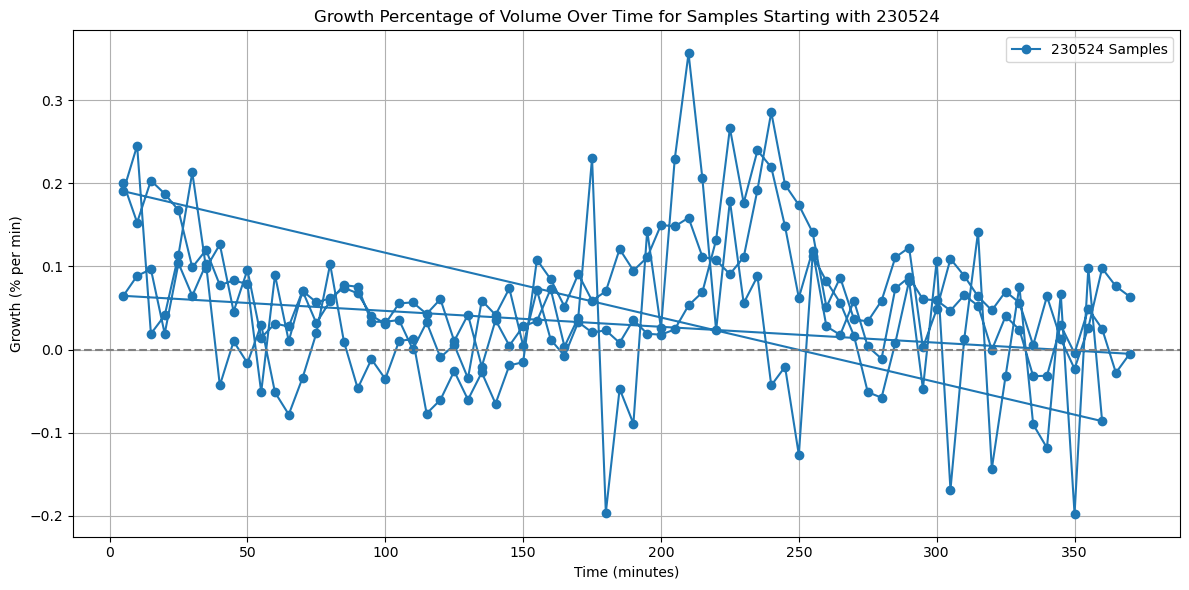

In [5]:
import matplotlib.pyplot as plt

# Sort WITHIN each embryo by time, then compute growth per embryo (do NOT mix files)
data.sort_values(by=['fname', 'Time'], inplace=True)

data['Volume Change'] = data.groupby('fname')['Volume in um³'].diff()   # um³
data['Time Step']     = data.groupby('fname')['Time'].diff()             # min
data['Growth'] = (data['Volume Change'] / data['Time Step']) / data['Volume in um³'] * 100  # % per min

# NaN-free copy (first frame of each embryo has no previous frame)
growth_data = data.dropna(subset=['Growth']).copy()

# Filter the data for samples starting with "230524"
filtered_data = growth_data[growth_data['fname'].str.startswith("230524")]

# Print the resulting DataFrame with growth percentages for filtered data
print(filtered_data[['fname', 'Time', 'Volume in um³', 'Growth']])

# Plotting the growth percentage for filtered data
plt.figure(figsize=(12, 6))

# Check if there are any filtered samples
if not filtered_data.empty:
    # Plotting the growth percentage for the filtered samples
    plt.plot(filtered_data['Time'], filtered_data['Growth'], marker='o', label='230524 Samples')

    # Adding titles and labels
    plt.title('Growth Percentage of Volume Over Time for Samples Starting with 230524')
    plt.xlabel('Time (minutes)')
    plt.ylabel('Growth (% per min)')
    plt.axhline(0, color='grey', linestyle='--')  # Add a horizontal line at y=0
    plt.legend()
    plt.grid()
    plt.tight_layout()

    # Show the plot
    plt.show()
else:
    print("No data available for samples starting with '230524'.")

C:\Users\apramos\AppData\Local\Temp\2\ipykernel_9140\2488003667.py:5: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(1,2,1)


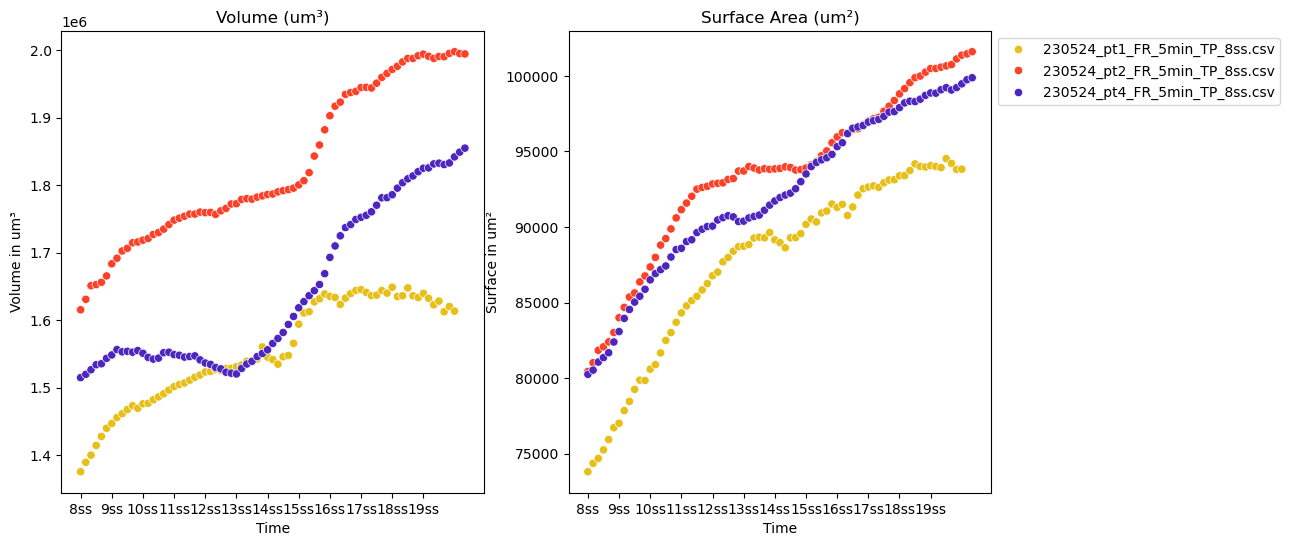

In [6]:
# Assuming 'data' is your DataFrame and has been defined
plt.subplots(figsize=(12,6))

# Subplot on the left
plt.subplot(1,2,1) 
sns.scatterplot(data=data, x='Time', y='Volume in um³', hue='fname', palette='CMRmap_r', legend=False)
plt.title("Volume (um³)")

# Setting custom x-axis tick labels and positions
max_xtic = data['dTime_min'].max() // 30 + min_ss
tic_labels = [str(i) + "ss" for i in range(min_ss, max_xtic)]
tics = [i * 30 for i in range(len(tic_labels))]
plt.xticks(tics, tic_labels)
# Set x-axis limits if necessary
# plt.xlim(left=min_ss, right=max_xtic * 30)  # Adjust right limit as needed

# Subplot on the right
plt.subplot(1,2,2)
sns.scatterplot(data=data, x='Time', y='Surface in um²', hue='fname', palette='CMRmap_r')
plt.legend(bbox_to_anchor=(1,1))
plt.title("Surface Area (um²)")
# Setting custom x-axis tick labels and positions
max_xtic = data['dTime_min'].max() // 30 + min_ss
tic_labels = [str(i) + "ss" for i in range(min_ss, max_xtic)]
tics = [i * 30 for i in range(len(tic_labels))]
plt.xticks(tics, tic_labels)
# Set x-axis limits if necessary
# plt.xlim(left=min_ss, right=max_xtic * 30)  # Adjust right limit as needed

# Save the figure to a file
plt.savefig("volume_surface_time2.png", bbox_inches='tight') 

# Show the plot (optional)
plt.show()




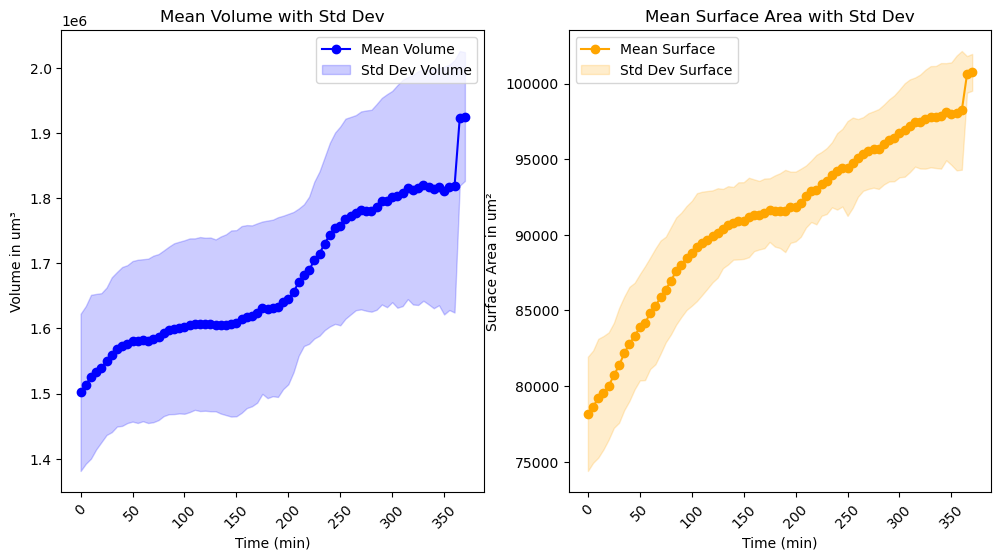

In [7]:
# New cell for plotting mean and std of Volume and Surface Area per time point
# Group by time and calculate mean and standard deviation
mean_data = data.groupby('Time').agg({
    'Volume in um³': ['mean', 'std'],
    'Surface in um²': ['mean', 'std']
}).reset_index()

# Flatten the MultiIndex columns
mean_data.columns = ['Time', 'Mean Volume', 'Std Volume', 'Mean Surface', 'Std Surface']

# Create the plot
plt.figure(figsize=(12, 6))

# Volume plot
plt.subplot(1, 2, 1)  # Subplot for Volume
plt.plot(mean_data['Time'], mean_data['Mean Volume'], marker='o', linestyle='-', color='blue', label='Mean Volume')
plt.fill_between(mean_data['Time'], 
                 mean_data['Mean Volume'] - mean_data['Std Volume'], 
                 mean_data['Mean Volume'] + mean_data['Std Volume'], 
                 color='blue', alpha=0.2, label='Std Dev Volume')
plt.title("Mean Volume with Std Dev")
plt.xlabel("Time (min)")
plt.ylabel("Volume in um³")
plt.legend()
plt.xticks(rotation=45)

# Surface Area plot
plt.subplot(1, 2, 2)  # Subplot for Surface Area
plt.plot(mean_data['Time'], mean_data['Mean Surface'], marker='o', linestyle='-', color='orange', label='Mean Surface')
plt.fill_between(mean_data['Time'], 
                 mean_data['Mean Surface'] - mean_data['Std Surface'], 
                 mean_data['Mean Surface'] + mean_data['Std Surface'], 
                 color='orange', alpha=0.2, label='Std Dev Surface')
plt.title("Mean Surface Area with Std Dev")
plt.xlabel("Time (min)")
plt.ylabel("Surface Area in um²")
plt.legend()
plt.xticks(rotation=45)

# Save the figure to a file
plt.savefig("mean_std_volume_surface_time.png", bbox_inches='tight')

# Show the plot (optional)
plt.show()

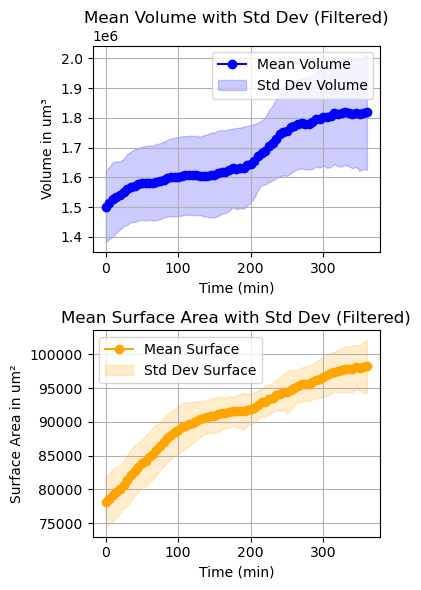

In [8]:
# New cell for filtering time points with at least 3 samples and plotting Volume and Surface Area separately
# Filter time points with at least 3 samples
valid_timepoints = data.groupby('Time').filter(lambda x: len(x) >= 3)

# Group by time and calculate mean and standard deviation for valid time points
mean_data = valid_timepoints.groupby('Time').agg({
    'Volume in um³': ['mean', 'std'],
    'Surface in um²': ['mean', 'std']
}).reset_index()

# Flatten the MultiIndex columns
mean_data.columns = ['Time', 'Mean Volume', 'Std Volume', 'Mean Surface', 'Std Surface']

# Create separate plots for Volume
plt.figure(figsize=(4, 6))

# Volume plot
plt.subplot(2, 1, 1)  # 2 rows, 1 column, 1st subplot
plt.plot(mean_data['Time'], mean_data['Mean Volume'], marker='o', linestyle='-', color='blue', label='Mean Volume')
plt.fill_between(mean_data['Time'], 
                 mean_data['Mean Volume'] - mean_data['Std Volume'], 
                 mean_data['Mean Volume'] + mean_data['Std Volume'], 
                 color='blue', alpha=0.2, label='Std Dev Volume')
plt.xlabel("Time (min)")
plt.ylabel("Volume in um³")
plt.title("Mean Volume with Std Dev (Filtered)")
plt.legend()
plt.grid()

# Create separate plots for Surface Area
plt.subplot(2, 1, 2)  # 2 rows, 1 column, 2nd subplot
plt.plot(mean_data['Time'], mean_data['Mean Surface'], marker='o', linestyle='-', color='orange', label='Mean Surface')
plt.fill_between(mean_data['Time'], 
                 mean_data['Mean Surface'] - mean_data['Std Surface'], 
                 mean_data['Mean Surface'] + mean_data['Std Surface'], 
                 color='orange', alpha=0.2, label='Std Dev Surface')
plt.xlabel("Time (min)")
plt.ylabel("Surface Area in um²")
plt.title("Mean Surface Area with Std Dev (Filtered)")
plt.legend()
plt.grid()

# Adjust layout to prevent overlap
plt.tight_layout()

# Save the figure to a file
plt.savefig("separate_mean_std_volume_surface_time.png", bbox_inches='tight')

# Show the plots (optional)
plt.show()

<Figure size 1200x600 with 0 Axes>

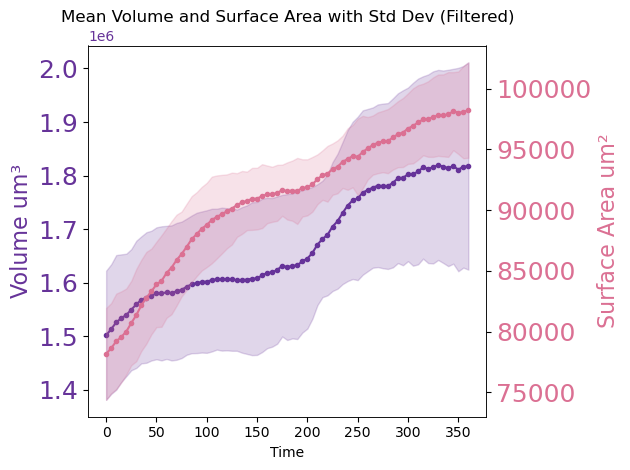

In [9]:
# New cell for filtering time points with at least 3 samples and overlapping mean and std of Volume and Surface Area
# Filter time points with at least 3 samples
valid_timepoints = data.groupby('Time').filter(lambda x: len(x) >= 3)

# Group by time and calculate mean and standard deviation for valid time points
mean_data = valid_timepoints.groupby('Time').agg({
    'Volume in um³': ['mean', 'std'],
    'Surface in um²': ['mean', 'std']
}).reset_index()

# Flatten the MultiIndex columns
mean_data.columns = ['Time', 'Mean Volume', 'Std Volume', 'Mean Surface', 'Std Surface']

# Create the overlapping plot
plt.figure(figsize=(12, 6))

# Plotting Volume
fig, ax1 = plt.subplots()

# Volume plot
ax1.plot(mean_data['Time'], mean_data['Mean Volume'], marker='.', linestyle='-', color='rebeccapurple')
        #label='Mean Volume')
ax1.fill_between(mean_data['Time'], 
                 mean_data['Mean Volume'] - mean_data['Std Volume'], 
                 mean_data['Mean Volume'] + mean_data['Std Volume'], 
                 color='rebeccapurple', alpha=0.2, label='Std Dev Volume')
ax1.set_xlabel("Time")
ax1.set_ylabel("Volume um³", color='rebeccapurple', fontsize=16)
ax1.tick_params(axis='y', labelcolor='rebeccapurple')
ax1.set_title("Mean Volume and Surface Area with Std Dev (Filtered)")
# Adjust y-axis tick font size
plt.yticks(fontsize=18)  # Adjust the tick size here

# Creating a secondary Y-axis for Surface Area
ax2 = ax1.twinx()

# Surface Area plot
ax2.plot(mean_data['Time'], mean_data['Mean Surface'], marker='.', linestyle='-', color='palevioletred') 
         #label='Mean Surface')
ax2.fill_between(mean_data['Time'], 
                 mean_data['Mean Surface'] - mean_data['Std Surface'], 
                 mean_data['Mean Surface'] + mean_data['Std Surface'], 
                 color='palevioletred', alpha=0.2, label='Std Dev Surface')
ax2.set_ylabel("Surface Area um²", color='palevioletred', fontsize=16)
ax2.tick_params(axis='y', labelcolor='palevioletred')

# Adjust y-axis tick font size
plt.yticks(fontsize=18)  # Adjust the tick size here
# Adding legends
#ax1.legend(loc='upper left')
#ax2.legend(loc='upper center')
# Set the thickness of the spines 
for spine in ax1.spines.values():
    spine.set_linewidth(0.5)  # Change the thickness value as needed

for spine in ax2.spines.values():
    spine.set_linewidth(0.5)  # Change the thickness value as needed

# Show grid for better visualization
#ax1.grid()
# Show plot
plt.tight_layout()
# Save the figure to a file 
plt.savefig("filtered_overlapped_mean_std_volume_surface_time.png", format='png', dpi=300 )
    #bbox_inches='tight'

# Show the plot (optional)
plt.show()

C:\Users\apramos\AppData\Local\Temp\2\ipykernel_9140\114628487.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=slope_df, x='fname', y='slope', palette='viridis')


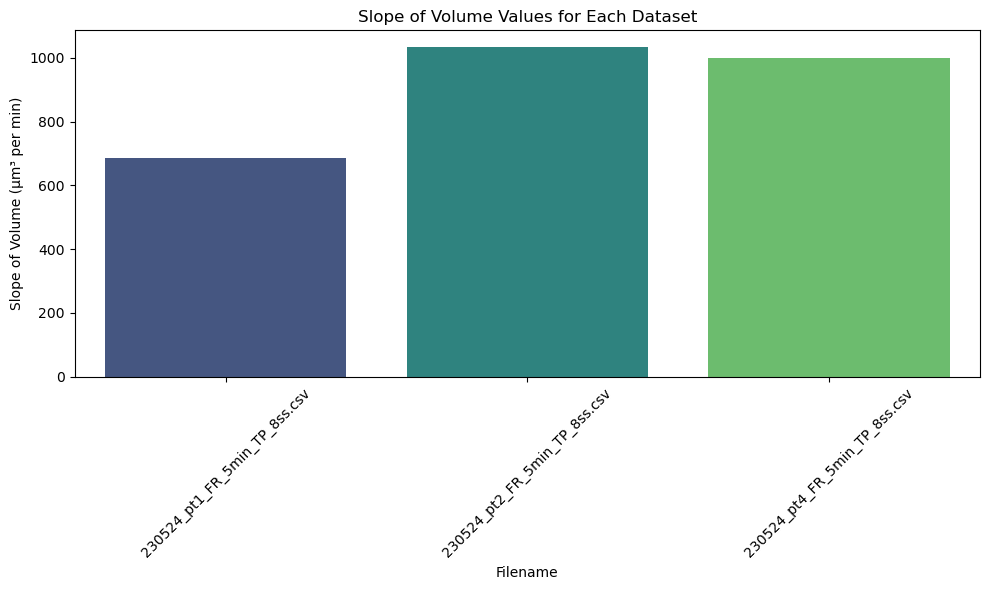

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time' and 'Volume in um³'

# Prepare to store slopes
slope_data = []

# Calculate the slope for each dataset
for fname in data['fname'].unique():
    subset = data[data['fname'] == fname]
    
    # Perform linear regression to get slope
    slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Volume in um³'])
    
    # Append the results
    slope_data.append({'fname': fname, 'slope': slope})

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Plotting the slopes
plt.figure(figsize=(10, 6))
sns.barplot(data=slope_df, x='fname', y='slope', palette='viridis')

# Adding titles and labels
plt.title('Slope of Volume Values for Each Dataset')
plt.xlabel('Filename')
plt.ylabel('Slope of Volume (µm³ per min)')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Show plot
plt.tight_layout()
plt.show()

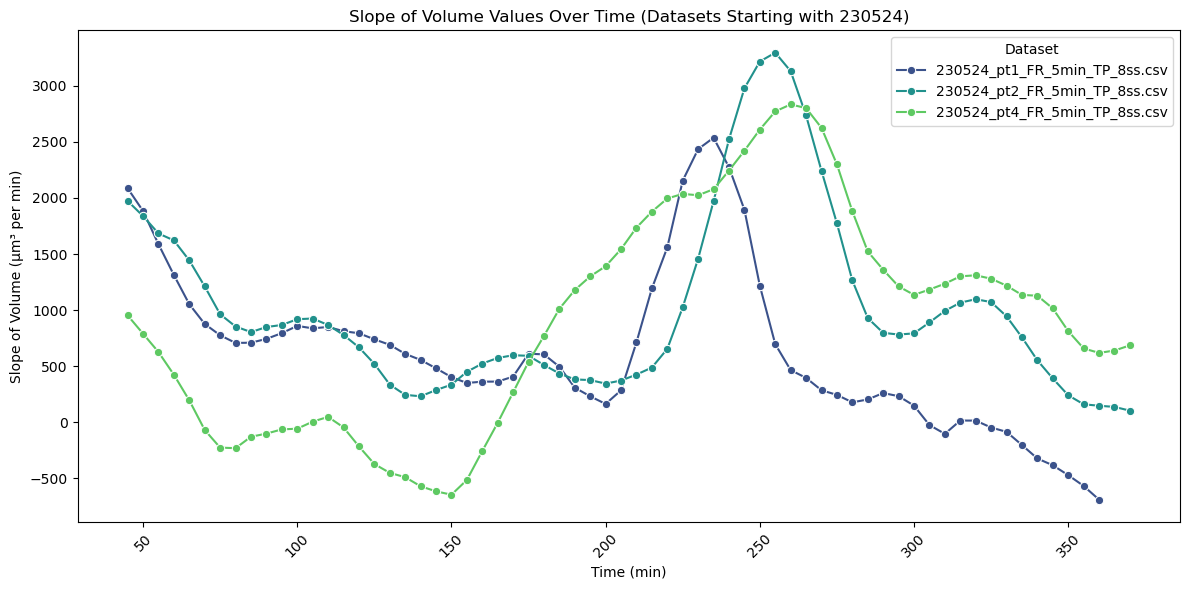

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time' and 'Volume in um³'
# Filter datasets that start with '230524'
#filtered_data = data[data['fname']]
filtered_data = data[data['fname'].str.startswith('230524')]

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 10

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Volume in um³'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope, 'Dataset': name})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Plotting the slopes per time point with different lines for each dataset
plt.figure(figsize=(12, 6))
sns.lineplot(data=slope_df, x='Time', y='Slope', hue='Dataset', marker='o', palette='viridis')

# Adding titles and labels
plt.title('Slope of Volume Values Over Time (Datasets Starting with 230524)')
plt.xlabel('Time (min)')
plt.ylabel('Slope of Volume (µm³ per min)')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Show plot
plt.tight_layout()
plt.show()

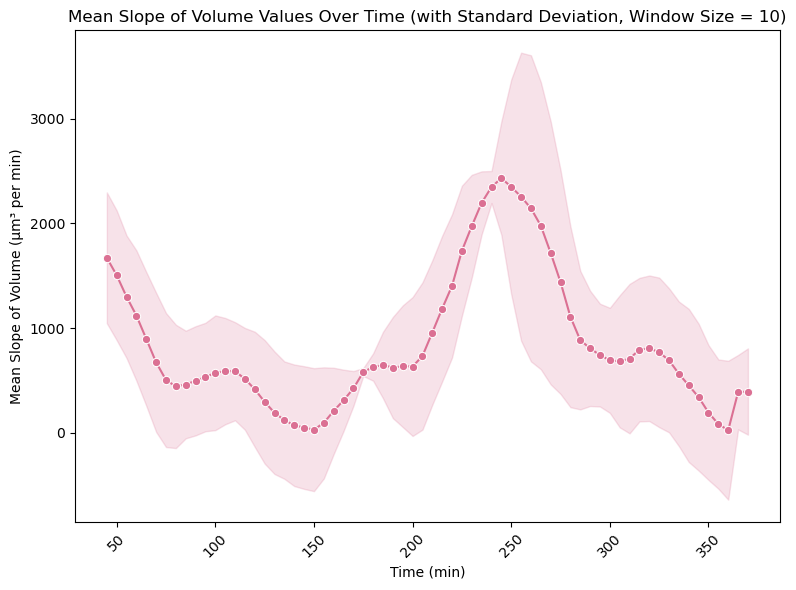

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time' and 'Volume in um³'
# Filter datasets that start with '230524'
filtered_data = data[data['fname'].str.startswith('230524')]

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 10

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Volume in um³'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Calculate the mean slope and standard deviation for each time point
mean_slope_df = slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                              std_dev=('Slope', 'std'))

# Plotting the mean slope with standard deviation
plt.figure(figsize=(8, 6))
sns.lineplot(data=mean_slope_df, x='Time', y='mean_slope', marker='o', color='palevioletred')

# Fill between the mean ± standard deviation
plt.fill_between(mean_slope_df['Time'], 
                 mean_slope_df['mean_slope'] - mean_slope_df['std_dev'], 
                 mean_slope_df['mean_slope'] + mean_slope_df['std_dev'], 
                 color='palevioletred', alpha=0.2)

# Adding titles and labels
plt.title(f'Mean Slope of Volume Values Over Time (with Standard Deviation, Window Size = {window_size})')
plt.xlabel('Time (min)')
plt.ylabel('Mean Slope of Volume (µm³ per min)')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Save the plot as a PNG file
plt.savefig(f'mean_slope_window_size_{window_size}.png', format='png', dpi=300)

# Show plot
plt.tight_layout()
plt.show()

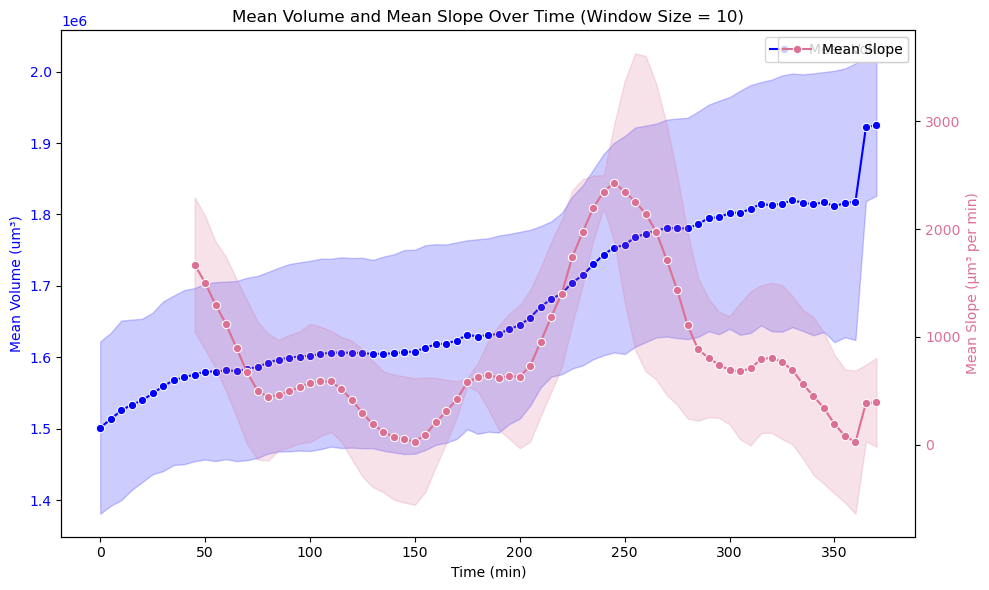

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time', 'Volume in um³', and 'fname'
# Filter datasets that start with '230524'
filtered_data = data[data['fname'].str.startswith('230524')]

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 10

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Volume in um³'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Calculate the mean slope and standard deviation for each time point
mean_slope_df = slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                              std_dev=('Slope', 'std'))

# Calculate mean volume and standard deviation for each time point
mean_volume_df = filtered_data.groupby('Time').agg(mean_volume=('Volume in um³', 'mean'),
                                                    std_volume=('Volume in um³', 'std')).reset_index()

# Plotting with dual y-axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot mean volume on the left y-axis
sns.lineplot(data=mean_volume_df, x='Time', y='mean_volume', marker='o', color='blue', ax=ax1, label='Mean Volume')
ax1.fill_between(mean_volume_df['Time'], 
                 mean_volume_df['mean_volume'] - mean_volume_df['std_volume'], 
                 mean_volume_df['mean_volume'] + mean_volume_df['std_volume'], 
                 color='blue', alpha=0.2)
ax1.set_ylabel('Mean Volume (um³)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Create a second y-axis for the mean slope
ax2 = ax1.twinx()
sns.lineplot(data=mean_slope_df, x='Time', y='mean_slope', marker='o', color='palevioletred', ax=ax2, label='Mean Slope')
ax2.fill_between(mean_slope_df['Time'], 
                 mean_slope_df['mean_slope'] - mean_slope_df['std_dev'], 
                 mean_slope_df['mean_slope'] + mean_slope_df['std_dev'], 
                 color='palevioletred', alpha=0.2)
ax2.set_ylabel('Mean Slope (µm³ per min)', color='palevioletred')
ax2.tick_params(axis='y', labelcolor='palevioletred')

# Adding titles and labels
plt.title(f'Mean Volume and Mean Slope Over Time (Window Size = {window_size})')
ax1.set_xlabel('Time (min)')

# Show plot
plt.tight_layout()

# Save the plot as a PNG file
plt.savefig(f'mean_volume_and_slope_window_size_{window_size}.png', format='png', dpi=300)

plt.show()

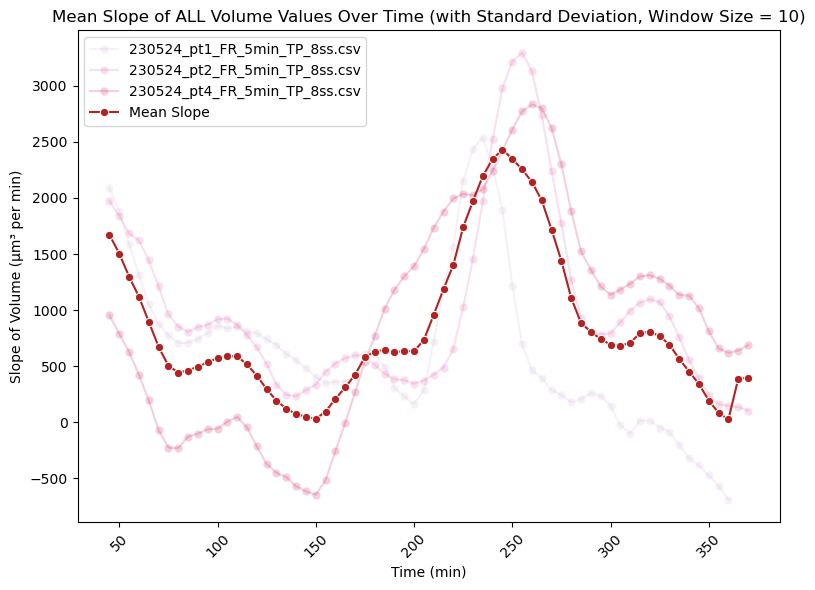

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time' and 'Volume in um³'
# Filter datasets that start with '230524'
filtered_data = data[data['fname'].str.startswith('230524')]

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 10

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Volume in um³'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope, 'Dataset': name})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Calculate the mean slope and standard deviation for each time point
mean_slope_df = slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                              std_dev=('Slope', 'std'))

# Plotting both the individual slopes and mean slope with standard deviation
plt.figure(figsize=(8, 6))

# Plot individual slopes for each dataset
sns.lineplot(data=slope_df, x='Time', y='Slope', hue='Dataset', marker='o', alpha=0.2, palette='PuRd')

# Plot mean slope
sns.lineplot(data=mean_slope_df, x='Time', y='mean_slope', marker='o', color='firebrick', label='Mean Slope')

"""
# Fill between the mean ± standard deviation
plt.fill_between(mean_slope_df['Time'], 
                 mean_slope_df['mean_slope'] - mean_slope_df['std_dev'], 
                 mean_slope_df['mean_slope'] + mean_slope_df['std_dev'], 
                 color='blue', alpha=0.2, label='Standard Deviation')
"""
# Adding titles and labels
# Adding titles and labels
plt.title(f'Mean Slope of ALL Volume Values Over Time (with Standard Deviation, Window Size = {window_size})')
plt.xlabel('Time (min)')
plt.ylabel('Slope of Volume (µm³ per min)')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Save the plot as a PNG file
plt.savefig(f'mean_slope_ALL_window_size_{window_size}.png', format='png', dpi=300)

# Show plot
plt.tight_layout()
plt.show()


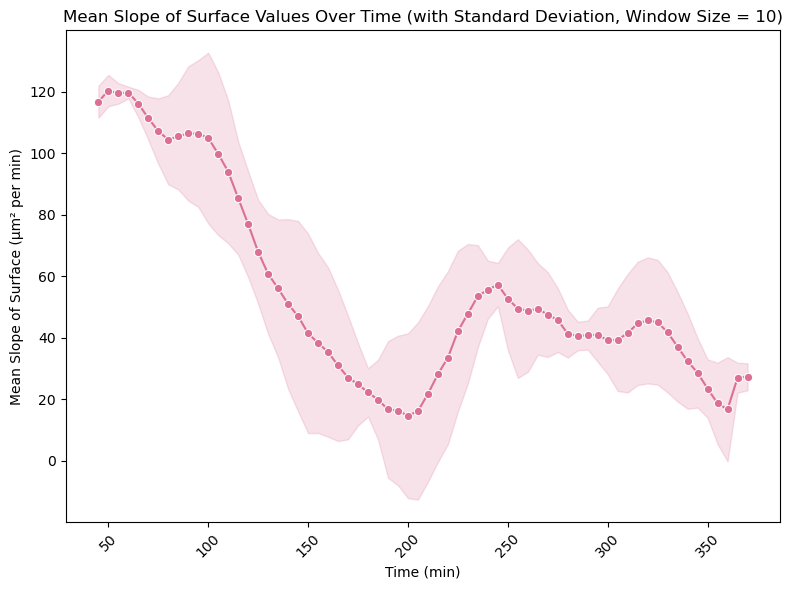

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time' and 'Volume in um³'
# Filter datasets that start with '230524'
filtered_data = data[data['fname'].str.startswith('230524')]

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 10

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Surface in um²'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Calculate the mean slope and standard deviation for each time point
mean_slope_df = slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                              std_dev=('Slope', 'std'))

# Plotting the mean slope with standard deviation
plt.figure(figsize=(8, 6))
sns.lineplot(data=mean_slope_df, x='Time', y='mean_slope', marker='o', color='palevioletred')

# Fill between the mean ± standard deviation
plt.fill_between(mean_slope_df['Time'], 
                 mean_slope_df['mean_slope'] - mean_slope_df['std_dev'], 
                 mean_slope_df['mean_slope'] + mean_slope_df['std_dev'], 
                 color='palevioletred', alpha=0.2)

# Adding titles and labels
plt.title(f'Mean Slope of Surface Values Over Time (with Standard Deviation, Window Size = {window_size})')
plt.xlabel('Time (min)')
plt.ylabel('Mean Slope of Surface (µm² per min)')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Save the plot as a PNG file
plt.savefig(f'mean_slope_surface_window_size_{window_size}.png', format='png', dpi=300)

# Show plot
plt.tight_layout()
plt.show()

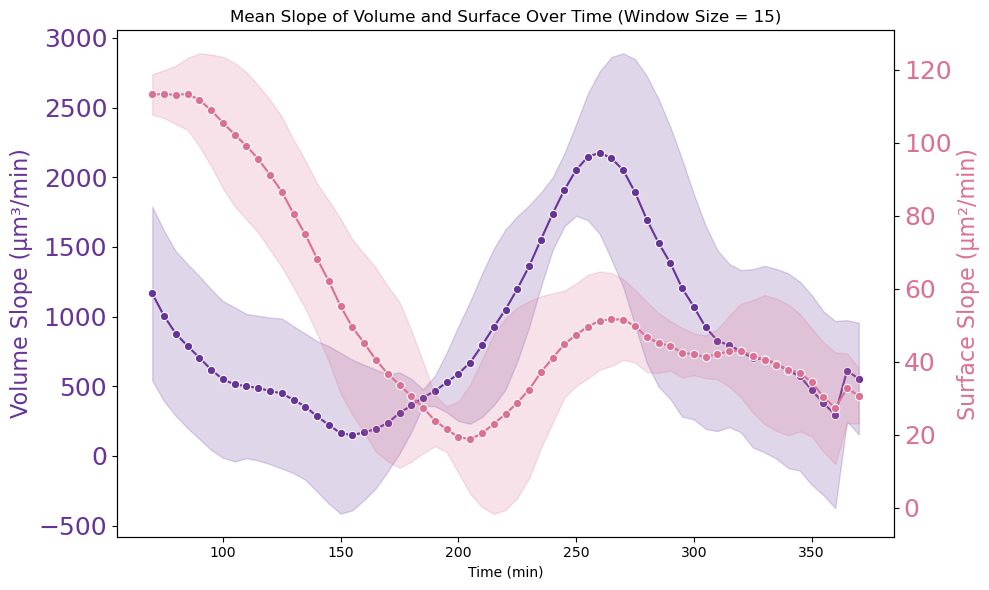

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time', 'Volume in um³', 'Surface in um²', and 'fname'
# Filter datasets that start with '230524'
filtered_data = data[data['fname'].str.startswith('230524')]

# Create lists to store slopes and corresponding time points for each dataset
volume_slope_data = []
surface_slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 15

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for volume and surface for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        volume_subset = group.iloc[i:i + window_size]
        surface_subset = group.iloc[i:i + window_size]
        
        if not volume_subset.empty:  # Check if there's data in the subset
            # Calculate slope for volume
            volume_slope, _, _, _, _ = linregress(volume_subset['Time'], volume_subset['Volume in um³'])
            volume_slope_data.append({'Time': volume_subset['Time'].iloc[-1], 'Slope': volume_slope})  # Use the last time point of the window
            
            # Calculate slope for surface
            surface_slope, _, _, _, _ = linregress(surface_subset['Time'], surface_subset['Surface in um²'])
            surface_slope_data.append({'Time': surface_subset['Time'].iloc[-1], 'Slope': surface_slope})  # Use the last time point of the window

# Create DataFrames for slopes
volume_slope_df = pd.DataFrame(volume_slope_data)
surface_slope_df = pd.DataFrame(surface_slope_data)

# Calculate the mean slope and standard deviation for each time point
mean_volume_slope_df = volume_slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                                           std_dev=('Slope', 'std'))
mean_surface_slope_df = surface_slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                                             std_dev=('Slope', 'std'))

# Plotting with dual y-axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot mean slope for volume on the left y-axis
sns.lineplot(data=mean_volume_slope_df, x='Time', y='mean_slope', marker='o', color='rebeccapurple', ax=ax1)
        #label='Mean Volume Slope')
ax1.fill_between(mean_volume_slope_df['Time'], 
                 mean_volume_slope_df['mean_slope'] - mean_volume_slope_df['std_dev'], 
                 mean_volume_slope_df['mean_slope'] + mean_volume_slope_df['std_dev'], 
                 color='rebeccapurple', alpha=0.2)
ax1.set_ylabel('Volume Slope (µm³/min)', color='rebeccapurple', fontsize=16)
ax1.tick_params(axis='y', labelcolor='rebeccapurple')
# Adjust y-axis tick font size
plt.yticks(fontsize=18)  # Adjust the tick size here


# Create a second y-axis for the mean surface slope
ax2 = ax1.twinx()
sns.lineplot(data=mean_surface_slope_df, x='Time', y='mean_slope', marker='o', color='palevioletred', ax=ax2)
             #label='Mean Surface Slope')"
ax2.fill_between(mean_surface_slope_df['Time'], 
                 mean_surface_slope_df['mean_slope'] - mean_surface_slope_df['std_dev'], 
                 mean_surface_slope_df['mean_slope'] + mean_surface_slope_df['std_dev'], 
                 color='palevioletred', alpha=0.2)
ax2.set_ylabel('Surface Slope (µm²/min)', color='palevioletred', fontsize=16)
ax2.tick_params(axis='y', labelcolor='palevioletred')

# Adding titles and labels
plt.title(f'Mean Slope of Volume and Surface Over Time (Window Size = {window_size})')
ax1.set_xlabel('Time (min)')

# Adjust y-axis tick font size
plt.yticks(fontsize=18)  # Adjust the tick size here

"""
# Set the thickness of the spines 
for spine in ax1.spines.values():
    spine.set_linewidth(0.5)  # Change the thickness value as needed

for spine in ax2.spines.values():
    spine.set_linewidth(0.5)  # Change the thickness value as needed
"""

# Show plot
plt.tight_layout()

# Save the plot as a PNG file
plt.savefig(f'mean_volume_and_surface_slope_window_size_{window_size}.png', format='png', dpi=300)

plt.show()

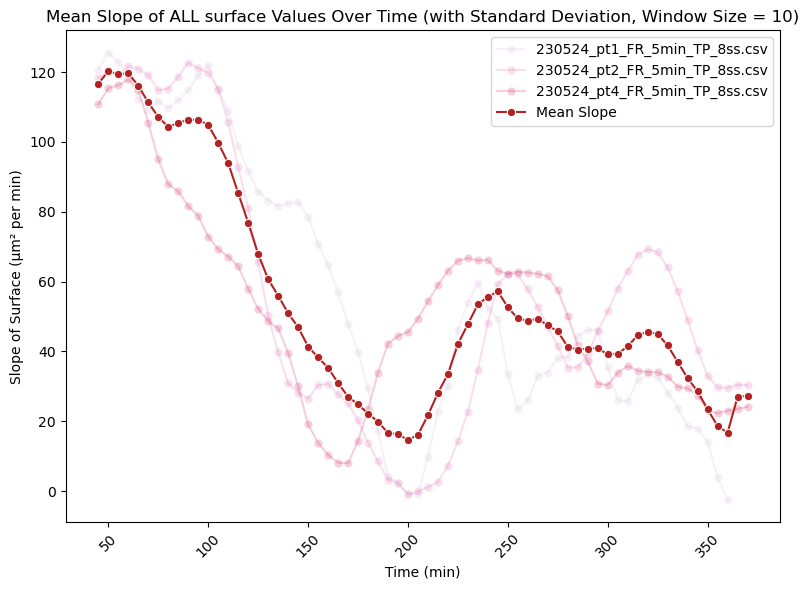

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Assuming 'data' is your DataFrame with 'Time' and 'Volume in um³'
# Filter datasets that start with '230524'
filtered_data = data[data['fname'].str.startswith('230524')]

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 10

# Group by dataset name
grouped_data = filtered_data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Surface in um²'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope, 'Dataset': name})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Calculate the mean slope and standard deviation for each time point
mean_slope_df = slope_df.groupby('Time', as_index=False).agg(mean_slope=('Slope', 'mean'),
                                                              std_dev=('Slope', 'std'))

# Plotting both the individual slopes and mean slope with standard deviation
plt.figure(figsize=(8, 6))

# Plot individual slopes for each dataset
sns.lineplot(data=slope_df, x='Time', y='Slope', hue='Dataset', marker='o', alpha=0.2, palette='PuRd')

# Plot mean slope
sns.lineplot(data=mean_slope_df, x='Time', y='mean_slope', marker='o', color='firebrick', label='Mean Slope')

"""
# Fill between the mean ± standard deviation
plt.fill_between(mean_slope_df['Time'], 
                 mean_slope_df['mean_slope'] - mean_slope_df['std_dev'], 
                 mean_slope_df['mean_slope'] + mean_slope_df['std_dev'], 
                 color='blue', alpha=0.2, label='Standard Deviation')
"""
# Adding titles and labels
# Adding titles and labels
plt.title(f'Mean Slope of ALL surface Values Over Time (with Standard Deviation, Window Size = {window_size})')
plt.xlabel('Time (min)')
plt.ylabel('Slope of Surface (µm² per min)')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Save the plot as a PNG file
plt.savefig(f'mean_slope_ALL_surface_window_size_{window_size}.png', format='png', dpi=300)

# Show plot
plt.tight_layout()
plt.show()


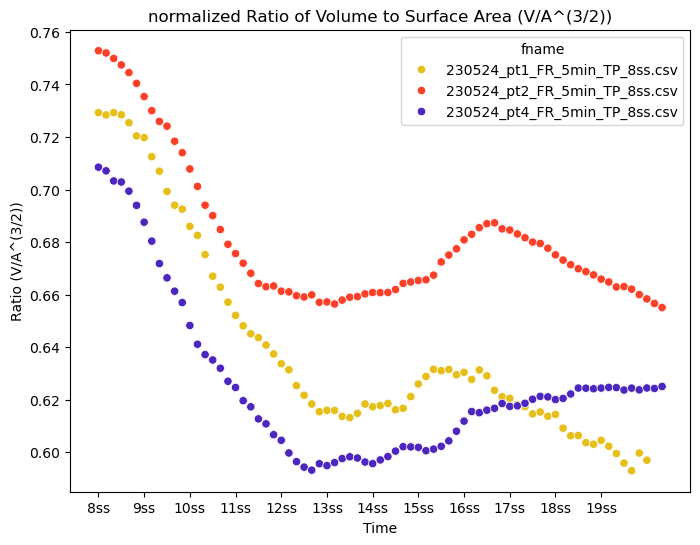

In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Assuming 'data' is your DataFrame and has been defined
# Calculate the ratio V / (A^(3/2))
#data['Ratio (V/A^(3/2))'] = data['Volume in um³'] / (data['Surface in um²'] ** (3/2))
data['Ratio (V/A^(3/2))'] = (data['Volume in um³'] / (data['Surface in um²'] ** (3/2)))/0.09403159725795938
plt.subplots(figsize=(8, 6))


sns.scatterplot(data=data, x='Time', y='Ratio (V/A^(3/2))', hue='fname', palette='CMRmap_r', legend=True)
plt.title("normalized Ratio of Volume to Surface Area (V/A^(3/2))")

# Setting custom x-axis tick labels and positions
plt.xticks(tics, tic_labels)

# Save the figure to a file
plt.savefig("normalized volume_surface_ratio_time.png", bbox_inches='tight')

# Show the plot (optional)
plt.show()

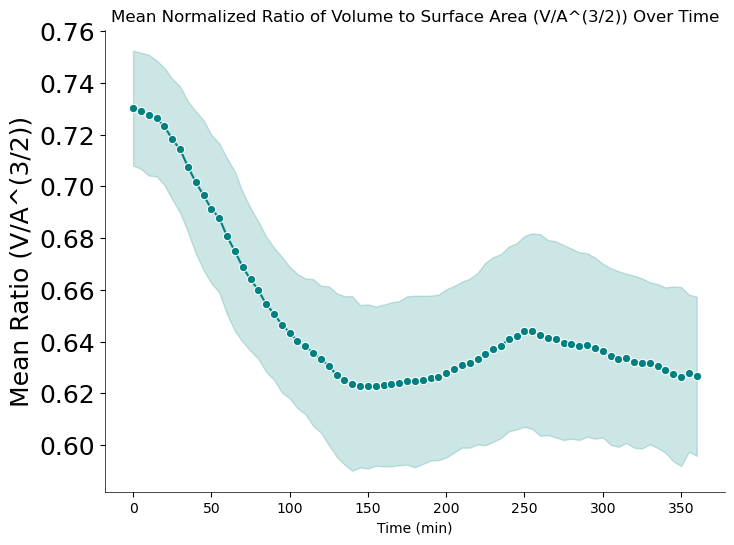

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Assuming 'data' is your DataFrame and has been defined
# Calculate the ratio V / (A^(3/2))
data['Ratio (V/A^(3/2))'] = (data['Volume in um³'] / (data['Surface in um²'] ** (3/2))) / 0.09403159725795938

# Count the number of samples for each time point
sample_counts = data['Time'].value_counts()

# Filter to keep only time points with at least 3 samples
valid_time_points = sample_counts[sample_counts >= 3].index

# Filter the original data to include only the valid time points
filtered_data = data[data['Time'].isin(valid_time_points)]

# Calculate mean and standard deviation of the ratio for each valid time point
mean_ratio_df = filtered_data.groupby('Time').agg(mean_ratio=('Ratio (V/A^(3/2))', 'mean'),
                                                  std_dev=('Ratio (V/A^(3/2))', 'std')).reset_index()

# Create the plot
plt.subplots(figsize=(8, 6))

# Plotting mean ratio with standard deviation
sns.lineplot(data=mean_ratio_df, x='Time', y='mean_ratio', marker='o', color='teal')
plt.fill_between(mean_ratio_df['Time'],
                 mean_ratio_df['mean_ratio'] - mean_ratio_df['std_dev'],
                 mean_ratio_df['mean_ratio'] + mean_ratio_df['std_dev'],
                 color='teal', alpha=0.2, label='Standard Deviation')

# Title and labels
plt.title("Mean Normalized Ratio of Volume to Surface Area (V/A^(3/2)) Over Time")
plt.xlabel("Time (min)")
plt.ylabel("Mean Ratio (V/A^(3/2))", fontsize=18)

# Adjust y-axis tick font size
plt.yticks(fontsize=18)  # Adjust the tick size here

# Remove the frame (spines) of the graph
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
# Set the thickness of the spines (frame)
for spine in plt.gca().spines.values():
    spine.set_linewidth(0.5)  # Change the thickness value as needed


#plt.legend()
#plt.legend(loc='upper right', fontsize=16, frameon=False, shadow=True, facecolor='lightgray')
# Save the figure to a file
plt.savefig("mean_normalized_volume_surface_ratio_time_filtered.png", bbox_inches='tight', format='png', dpi=300)

# Show the plot
plt.show()

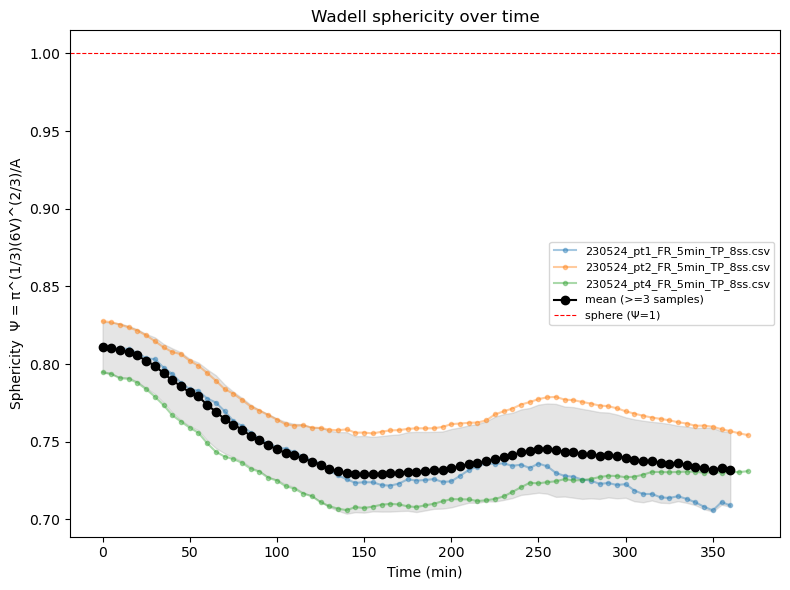

In [20]:
# True Wadell sphericity over time (per embryo + mean of time points with >=3 samples)
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
for name, g in data.groupby('fname'):
    plt.plot(g['Time'], g['Sphericity'], marker='.', alpha=0.4, label=name)

counts = data['Time'].value_counts()
valid = counts[counts >= 3].index
m = data[data['Time'].isin(valid)].groupby('Time')['Sphericity'].agg(['mean', 'std']).reset_index()
plt.plot(m['Time'], m['mean'], color='black', marker='o', label='mean (>=3 samples)')
plt.fill_between(m['Time'], m['mean'] - m['std'], m['mean'] + m['std'], color='grey', alpha=0.2)

plt.axhline(1.0, color='red', linestyle='--', linewidth=0.8, label='sphere (Ψ=1)')
plt.xlabel('Time (min)')
plt.ylabel('Sphericity  Ψ = π^(1/3)(6V)^(2/3)/A')
plt.title('Wadell sphericity over time')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('sphericity_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

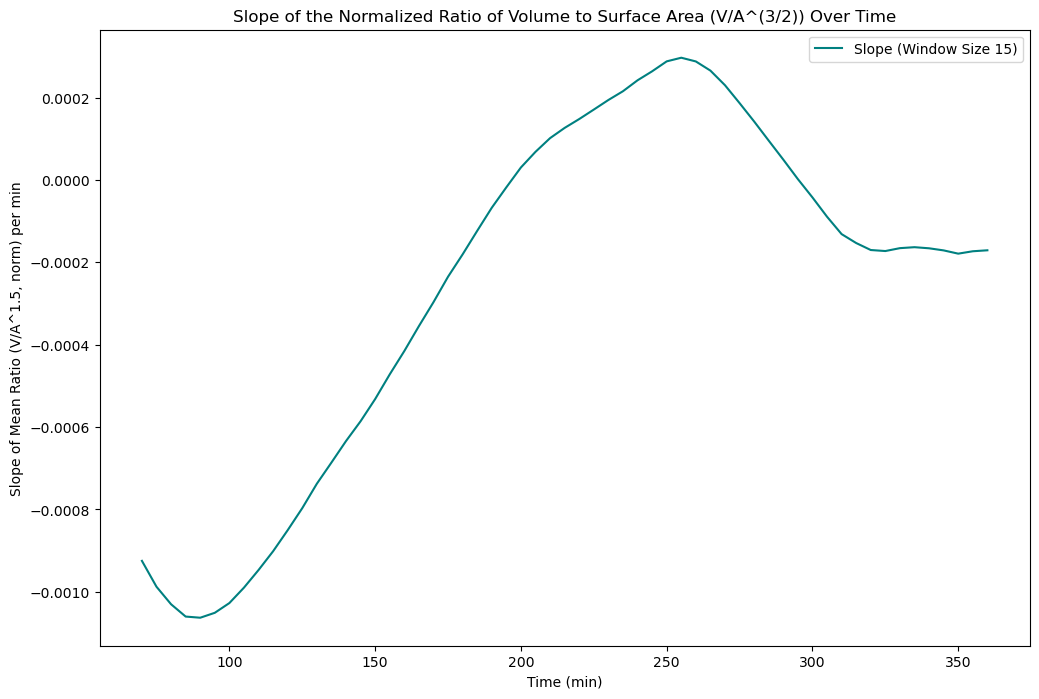

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

# Assuming 'data' is your DataFrame and has been defined
# Calculate the ratio V / (A^(3/2))
data['Ratio (V/A^(3/2))'] = (data['Volume in um³'] / (data['Surface in um²'] ** (3/2))) / 0.09403159725795938

# Count the number of samples for each time point
sample_counts = data['Time'].value_counts()

# Filter to keep only time points with at least 3 samples
valid_time_points = sample_counts[sample_counts >= 3].index

# Filter the original data to include only the valid time points
filtered_data = data[data['Time'].isin(valid_time_points)]

# Calculate the ratio for each valid time point
mean_ratio_df = filtered_data.groupby('Time').agg(mean_ratio=('Ratio (V/A^(3/2))', 'mean')).reset_index()

# Calculate the slope of the ratio with a rolling window of size 15
window_size = 15
mean_ratio_df['slope'] = np.nan

for i in range(len(mean_ratio_df) - window_size + 1):
    # Select the current window
    window_data = mean_ratio_df.iloc[i:i + window_size]
    
    # Fit a linear regression model to the window data
    X = window_data['Time'].values.reshape(-1, 1)  # regress against Time in minutes
    y = window_data['mean_ratio'].values
    model = LinearRegression().fit(X, y)
    
    # The slope (coefficient) of the line is the first element of the coefficients
    mean_ratio_df.loc[i + window_size - 1, 'slope'] = model.coef_[0]

# Create the plot for just the slope
plt.subplots(figsize=(12, 8))

# Plotting the slope of the ratio
plt.plot(mean_ratio_df['Time'], mean_ratio_df['slope'], color='teal', label='Slope (Window Size 15)', linestyle='-')

# Title and labels
plt.title("Slope of the Normalized Ratio of Volume to Surface Area (V/A^(3/2)) Over Time")
plt.xlabel("Time (min)")
plt.ylabel("Slope of Mean Ratio (V/A^1.5, norm) per min")
plt.legend()

# Save the figure to a file
plt.savefig("slope_of_volume_surface_ratio_time.png", bbox_inches='tight')

# Show the plot
plt.show()

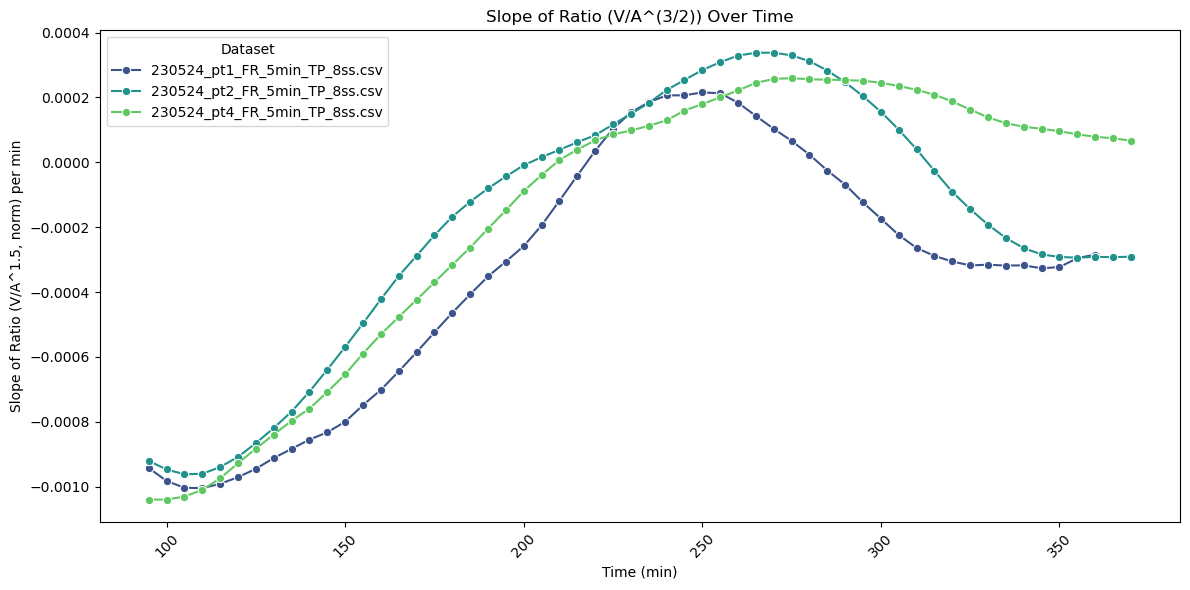

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Assuming 'data' is your DataFrame and has been defined
# Calculate the ratio V / (A^(3/2))
data['Ratio (V/A^(3/2))'] = (data['Volume in um³'] / (data['Surface in um²'] ** (3/2))) / 0.09403159725795938  # normalised: =1 for a sphere

# Create a list to store slopes and corresponding time points for each dataset
slope_data = []

# Define the window size for slope calculation (e.g., look at the previous 10 time points)
window_size = 20

# Group by dataset name
grouped_data = data.groupby('fname')

# Calculate the slope for each dataset
for name, group in grouped_data:
    for i in range(len(group) - window_size + 1):
        subset = group.iloc[i:i + window_size]
        
        if not subset.empty:  # Check if there's data in the subset
            slope, intercept, r_value, p_value, std_err = linregress(subset['Time'], subset['Ratio (V/A^(3/2))'])
            slope_data.append({'Time': subset['Time'].iloc[-1], 'Slope': slope, 'Dataset': name})  # Use the last time point of the window

# Create a DataFrame for slopes
slope_df = pd.DataFrame(slope_data)

# Plotting the slopes per time point with different lines for each dataset
plt.figure(figsize=(12, 6))
sns.lineplot(data=slope_df, x='Time', y='Slope', hue='Dataset', marker='o', palette='viridis')

# Adding titles and labels
plt.title('Slope of Ratio (V/A^(3/2)) Over Time')
plt.xlabel('Time (min)')
plt.ylabel('Slope of Ratio (V/A^1.5, norm) per min')
plt.xticks(rotation=45)  # Rotate x labels for better readability

# Save the plot as a PNG file
plt.savefig(f'Volume surface ratio slope_window_size_{window_size}.png', format='png', dpi=300)


# Show plot
plt.tight_layout()
plt.show()

In [23]:
# Extract and print volume data for Time=12ss
time_12ss = (12 - data['SS'].min()) * 30  # Calculate the time for 12ss
filtered_data = data[data['Time'] == time_12ss]

# Select relevant columns: you might want the file name, time, and volume data
filtered_data = filtered_data[['fname', 'Time', 'Volume in um³']]

# Print the results
print(filtered_data)

                            fname  Time  Volume in um³
24  230524_pt1_FR_5min_TP_8ss.csv   120   1.523126e+06
24  230524_pt2_FR_5min_TP_8ss.csv   120   1.759364e+06
24  230524_pt4_FR_5min_TP_8ss.csv   120   1.536376e+06


In [24]:
import pandas as pd
import os

# Assuming 'data' is the concatenated DataFrame from the previous code
# and that 'files' is the list of input file names.

# Create a directory to save the new CSV files, if it doesn't exist
output_dir = 'output_csvs'
os.makedirs(output_dir, exist_ok=True)

# Create a DataFrame to store all the volume data
consolidated_volume_data = pd.DataFrame()

# Iterate through the original files again to extract Time, Volume, and Surface
for file in files:
    fname = file.split("\\")[-1]
    
    # Extract the relevant DataFrame for the current file
    # Filter the data to keep only the relevant rows
    filtered_data = data[data['fname'] == fname][['Time', 'Volume in um³', 'Surface in um²']]
    
    # Add a new column to identify the source file
    filtered_data['Source File'] = fname
    
    # Append the filtered data to the consolidated DataFrame
    consolidated_volume_data = pd.concat([consolidated_volume_data, filtered_data], ignore_index=True)

# Define the output CSV filename for the consolidated data
output_csv_file = os.path.join(output_dir, 'consolidated_volume_data.csv')

# Write the consolidated DataFrame to a new CSV file
consolidated_volume_data.to_csv(output_csv_file, index=False)

# Print confirmation
print(f"Created {output_csv_file} with columns: {consolidated_volume_data.columns.tolist()}")

Created output_csvs\consolidated_volume_data.csv with columns: ['Time', 'Volume in um³', 'Surface in um²', 'Source File']
